# Bike sharing forecasting with SHAPformer (UCI Bike Sharing)

This notebook trains a SHAPformer model on the **Bike Sharing** dataset from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset): hourly counts of rented bikes of the Capital Bikeshare system in Washington, D.C., in 2011 and 2012, together with calendar and weather information.

1. download and load the data,
2. build a dataframe with the target and calendar and weather covariates,
3. inspect the covariates and the length of the time series,
4. retrain a model at the beginning of every month of 2012 (or load the trained models),
5. evaluate the models on the validation (January–June 2012) and test (July–December 2012) period,
6. explain one forecast, and show dependence plots of 1000 explanations.

The switch `TRAINING` decides whether the models are trained from scratch and saved to `MODEL_DIR` (`True`), or whether the trained models are loaded from `MODEL_DIR` (`False`).

In [1]:
%load_ext autoreload
%autoreload 2

import io
import urllib.request
import zipfile

import pandas as pd
import torch

import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

from src.models.shapformer import SHAPformer

TRAINING = True  # True: train the models from scratch and save them to MODEL_DIR; False: load the trained models from MODEL_DIR
MODEL_DIR = Path("bike_sharing_models")  # one model per forecast month: <year>-<month>.ckpt
SEED = 42

## Load the data

The dataset is not part of fev-bench, so we download the zip archive from the UCI repository once and cache it in `data/bike_sharing/`. The archive contains a daily (`day.csv`) and an hourly (`hour.csv`) version; we use the hourly one. Each row is one hour, given by the date `dteday` and the hour `hr`. The target is the total number of rentals `cnt`, which is the sum of the rentals by casual users (`casual`) and by registered users (`registered`).

In [2]:
DATA_URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
DATA_PATH = Path("data/bike_sharing/bike_sharing_dataset.zip")

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    DATA_PATH.write_bytes(urllib.request.urlopen(DATA_URL).read())

with zipfile.ZipFile(DATA_PATH) as archive:
    raw = pd.read_csv(io.BytesIO(archive.read("hour.csv")))
raw

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61


## Build the dataframe

The dataframe has one row per hour, indexed by the timestamp (local time in Washington, D.C.). It contains the target `rentals` (`cnt`) and the covariates:

- calendar features: `hour_of_day`, `day_of_week` (0 = Monday), `month` and `holiday` (1 on public holidays in Washington, D.C., as given in the dataset, else 0),
- weather features: `weather` (the weather situation: 0 = clear or partly cloudy, 1 = mist or cloudy, 2 = rain, snow or thunderstorm), the temperature `temperature` and the felt temperature `felt_temperature` in °C, the relative humidity `humidity` in % and the wind speed `wind_speed` in km/h.

The dataset stores the temperatures, the humidity and the wind speed divided by their maximum (41 °C, 50 °C, 100 % and 67 km/h); we multiply them back to their original units. Categorical features must be integers starting at 0, so `month` is shifted from 1–12 to 0–11. The dataset distinguishes four weather situations, but the fourth one (heavy rain, snow or thunderstorm) occurs in only 3 hours, so we merge it with the third one (light rain or snow) and shift the categories from 1–3 to 0–2. The weather is observed, not forecast, so during the forecast horizon these covariates act as a perfect weather forecast. We do not use `casual` and `registered`, since they add up to the target.

The dataset has no rows for hours without any rentals (its smallest count is 1). We add these hours and treat them depending on the length of the gap:

- **Short gaps** of at most `MAX_FILLED_GAP` = 2 hours are quiet night hours (all of them lie between 0 and 6 h) and the non-existent hours at the switch to daylight saving time. We fill them with 0 rentals. The weather was not recorded because the row is missing, so we interpolate the continuous weather features linearly and take the weather situation of the previous hour.
- **Long gaps** of 3 hours or more are shutdowns during storms: the snowstorms in January 2011, Hurricane Irene (27–28 August 2011) and Hurricane Sandy (29–30 October 2012), and one night in February 2011. Probably no bikes were rented, but the covariates cannot tell the model that the system is shut down: hours with rain and strong wind usually still have many rentals. We therefore set the target and the weather to missing (`NaN`). `fit` only trains on windows of 336 consecutive hours without missing values, so it skips the shutdowns. The calendar features are known for every hour.

In [3]:
timestamps = pd.to_datetime(raw["dteday"]) + pd.to_timedelta(raw["hr"], unit="h")
data = raw.set_index(pd.DatetimeIndex(timestamps, name="timestamp"))

MAX_FILLED_GAP = 2  # gaps of at most this many hours are filled; longer gaps are shutdowns and stay missing

index = pd.date_range(data.index[0], data.index[-1], freq="h", name="timestamp")
missing = pd.Series(~index.isin(data.index), index=index)
gap_length = missing.groupby((missing != missing.shift()).cumsum()).transform("size")
short_gap = missing & (gap_length <= MAX_FILLED_GAP)
long_gap = missing & (gap_length > MAX_FILLED_GAP)
print(f"Hours without rows in the dataset: {missing.sum()}, "
      f"of which {short_gap.sum()} in short gaps (filled) and {long_gap.sum()} in long gaps (missing)")

df = pd.DataFrame(index=index)
df["rentals"] = data["cnt"].reindex(index)
df.loc[short_gap, "rentals"] = 0

holidays = set(pd.to_datetime(raw.loc[raw["holiday"] == 1, "dteday"]).dt.date)
df["hour_of_day"] = index.hour
df["day_of_week"] = index.day_of_week
df["month"] = index.month - 1  # categorical features must start at 0
df["holiday"] = [int(date in holidays) for date in index.date]

weather = pd.DataFrame(
    {
        "weather": data["weathersit"].clip(upper=3) - 1,  # merge situations 3 and 4; categories must start at 0
        "temperature": data["temp"] * 41,
        "felt_temperature": data["atemp"] * 50,
        "humidity": data["hum"] * 100,
        "wind_speed": data["windspeed"] * 67,
    }
).reindex(index)
weather["weather"] = weather["weather"].ffill().astype("Int64")  # integer categories with missing values
continuous_weather = ["temperature", "felt_temperature", "humidity", "wind_speed"]
weather[continuous_weather] = weather[continuous_weather].interpolate()
weather[long_gap] = pd.NA
df = df.join(weather)
print(df)

Hours without rows in the dataset: 165, of which 76 in short gaps (filled) and 89 in long gaps (missing)
                     rentals  hour_of_day  day_of_week  month  holiday  \
timestamp                                                                
2011-01-01 00:00:00     16.0            0            5      0        0   
2011-01-01 01:00:00     40.0            1            5      0        0   
2011-01-01 02:00:00     32.0            2            5      0        0   
2011-01-01 03:00:00     13.0            3            5      0        0   
2011-01-01 04:00:00      1.0            4            5      0        0   
...                      ...          ...          ...    ...      ...   
2012-12-31 19:00:00    119.0           19            0     11        0   
2012-12-31 20:00:00     89.0           20            0     11        0   
2012-12-31 21:00:00     90.0           21            0     11        0   
2012-12-31 22:00:00     61.0           22            0     11        0   
2012-12

## Length of the time series and covariate statistics

Since a single missing hour excludes every window of 336 hours that contains it, we also count the windows without missing values that `fit` can use.

In [4]:
WINDOW_LENGTH = 336  # 168 hours input + 168 hours forecast

covariates = [c for c in df.columns if c != "rentals"]
incomplete = df.isna().any(axis=1)
complete_windows = incomplete.rolling(WINDOW_LENGTH).sum().iloc[WINDOW_LENGTH - 1:] == 0
print(f"Length: {len(df)} hours ({len(df) / 24 / 365.25:.1f} years), from {df.index[0]} to {df.index[-1]}")
print(f"Rows with missing values: {incomplete.sum()}")
print(f"Windows without missing values: {complete_windows.sum()} of {len(complete_windows)} "
      f"({complete_windows.mean():.1%})")
print("Hours per weather situation:", {int(k): int(v) for k, v in df["weather"].value_counts().sort_index().items()})
df.describe().T.assign(missing=df.isna().sum())

Length: 17544 hours (2.0 years), from 2011-01-01 00:00:00 to 2012-12-31 23:00:00
Rows with missing values: 89
Windows without missing values: 15582 of 17209 (90.5%)
Hours per weather situation: {0: 11455, 1: 4563, 2: 1437}


,count,mean,std,min,25%,50%,75%,max,missing
rentals,17455.0,188.638155,181.421666,0.0,39.0,141.0,280.0,977.0,89
hour_of_day,17544.0,11.5,6.922384,0.0,5.75,11.5,17.25,23.0,0
day_of_week,17544.0,3.002736,2.003472,0.0,1.0,3.0,5.0,6.0,0
month,17544.0,5.519836,3.449649,0.0,3.0,6.0,9.0,11.0,0
holiday,17544.0,0.028728,0.167045,0.0,0.0,0.0,0.0,1.0,0
weather,17455.0,0.426067,0.639695,0.0,0.0,0.0,1.0,2.0,89
temperature,17455.0,20.331608,7.913569,0.82,13.94,20.5,27.06,41.0,89
felt_temperature,17455.0,23.73969,8.613316,0.0,16.665,24.24,31.06,50.0,89
humidity,17455.0,62.745832,19.298307,0.0,48.0,63.0,78.0,100.0,89
wind_speed,17455.0,12.735138,8.19428,0.0,7.0015,12.998,16.9979,56.9969,89


## Monthly retraining

The number of rentals grew strongly from 2011 to 2012, so we retrain a new model at the beginning of every month of 2012 with all data up to that month. The model of month M

- is trained on all data before month M − 1 (from January 2011 on),
- is validated on month M − 1 (the validation forecasts start in M − 1 and their full forecast week lies within M − 1),
- forecasts from every midnight in month M; the forecast weeks may reach into the next month.

`fit` only gets the data before month M, so the model never sees data of its forecast month. The forecasts of January–June 2012 form the validation period, those of July–December 2012 the test period. `fit` skips all windows that contain missing values (the shutdowns).

In [5]:
FIRST_FORECAST_MONTH = pd.Timestamp("2012-01-01")
TEST_START = pd.Timestamp("2012-07-01")

forecast_months = pd.date_range(FIRST_FORECAST_MONTH, df.index[-1], freq="MS")
for month in forecast_months:
    validation_start = month - pd.DateOffset(months=1)
    period = "validation" if month < TEST_START else "test"
    print(f"{month:%Y-%m} ({period}): training {df.index[0]:%Y-%m-%d} to {validation_start - pd.Timedelta(days=1):%Y-%m-%d}, "
          f"validation {validation_start:%Y-%m}")

2012-01 (validation): training 2011-01-01 to 2011-11-30, validation 2011-12
2012-02 (validation): training 2011-01-01 to 2011-12-31, validation 2012-01
2012-03 (validation): training 2011-01-01 to 2012-01-31, validation 2012-02
2012-04 (validation): training 2011-01-01 to 2012-02-29, validation 2012-03
2012-05 (validation): training 2011-01-01 to 2012-03-31, validation 2012-04
2012-06 (validation): training 2011-01-01 to 2012-04-30, validation 2012-05
2012-07 (test): training 2011-01-01 to 2012-05-31, validation 2012-06
2012-08 (test): training 2011-01-01 to 2012-06-30, validation 2012-07
2012-09 (test): training 2011-01-01 to 2012-07-31, validation 2012-08
2012-10 (test): training 2011-01-01 to 2012-08-31, validation 2012-09
2012-11 (test): training 2011-01-01 to 2012-09-30, validation 2012-10
2012-12 (test): training 2011-01-01 to 2012-10-31, validation 2012-11


## Create the models

Each model predicts the `rentals` from the covariates in `feature_categories`: for each covariate, the number of categories, or `None` for a continuous feature. As in the other examples, we use a small transformer with one layer, four attention heads and a hidden dimension of 128.

With `instance_norm="RevIN"` (reversible instance normalization), the past rentals of each forecast are normalized with their own mean and standard deviation before they enter the network, and the forecast is denormalized with the same statistics. The model therefore forecasts relative to the level of the past week and adapts to the growth of the rentals. The statistics are always computed from the full past week, so the explanations stay additive: the level of the past week is part of the base value.

In [6]:
FEATURE_CATEGORIES = {
    "hour_of_day": 24,
    "day_of_week": 7,
    "month": 12,
    "holiday": 2,
    "weather": 3,
    "temperature": None,
    "felt_temperature": None,
    "humidity": None,
    "wind_speed": None,
}


def create_model():
    return SHAPformer(
        target="rentals",
        feature_categories=FEATURE_CATEGORIES,
        d_model=128,
        n_layers=1,
        n_heads=4,
        instance_norm="RevIN",
    )

## Train the models (or load the trained models)

For each month, `model.fit(data, validation_start)` trains on the rows before `validation_start` and computes the validation loss on the rows from `validation_start` on. Training runs for at most 20 epochs and stops early when the validation loss has not improved for 10 epochs; the model with the lowest validation loss is restored. Every model is trained from scratch with the same seed.

The models are stored in the dictionary `models`, which maps the first day of each forecast month to its model. With `TRAINING = True`, each model is saved to `MODEL_DIR/<year>-<month>.ckpt`; with `TRAINING = False`, the models are loaded from there.

In [7]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 20

models = {}
for month in forecast_months:
    path = MODEL_DIR / f"{month:%Y-%m}.ckpt"
    if TRAINING:
        print(f"===== Model for {month:%Y-%m}")
        torch.manual_seed(SEED)
        model = create_model().to(DEVICE)
        model = model.fit(df[df.index < month], month - pd.DateOffset(months=1), epochs=EPOCHS, batch_size=128)
        MODEL_DIR.mkdir(exist_ok=True)
        torch.save(model, path)
    else:
        model = torch.load(path, map_location=DEVICE, weights_only=False)
        model.eval()
    models[month] = model


def model_for(start):
    # the model of the month in which the forecast starts (start: position in df)
    return models[df.index[start].to_period("M").to_timestamp()]

===== Model for 2012-01


Using 6425 of 7681 training windows; the others contain missing values or missing time steps.


  0%|          | 0/51 [00:00<?, ?it/s]

  2%|▏         | 1/51 [00:00<00:39,  1.27it/s]

  4%|▍         | 2/51 [00:00<00:18,  2.58it/s]

  6%|▌         | 3/51 [00:01<00:12,  3.86it/s]

... (20,200 outputs left out)

 98%|█████████▊| 111/113 [00:12<00:00,  9.21it/s]

 99%|█████████▉| 112/113 [00:12<00:00,  9.29it/s]

100%|██████████| 113/113 [00:12<00:00,  9.25it/s]

Epoch 20/20, Training loss: 0.2520282848746376, Validation loss: 0.15392933785915375 (best: 0.15392933785915375), Epochs without improvement: 0/10
Restored the model from epoch 20 with validation loss 0.15392933785915375.


## Evaluate the models on the validation and test data

We forecast one week (168 hours) from every midnight of 2012 with the model of the month in which the forecast starts. The forecast weeks may reach into the next month, but must end by 31 December 2012. Forecasts whose input or forecast week contains missing values (a shutdown) are skipped. We report the mean absolute error (MAE) and the root mean squared error (RMSE) in rentals per hour, over the full week and over the first 24 hours, for each month and for the validation (January–June) and test (July–December) period. As a reference, we compare with the weekly seasonal naive forecast, which repeats the rentals of the week before.

In [8]:
import numpy as np

INPUT_LENGTH = HORIZON = 168

complete = ~df.isna().any(axis=1).to_numpy()


def is_complete(start):
    # no missing values in the input week and the forecast week
    return complete[start - INPUT_LENGTH:start + HORIZON].all()


def metrics(actual, forecast):
    error = forecast - actual
    return {
        "MAE (168 h)": np.abs(error).mean(),
        "RMSE (168 h)": np.sqrt((error ** 2).mean()),
        "MAE (24 h)": np.abs(error[:, :24]).mean(),
        "RMSE (24 h)": np.sqrt((error[:, :24] ** 2).mean()),
    }


# forecasts from every midnight of 2012 whose forecast week ends by the end of the data
positions = np.flatnonzero((df.index >= FIRST_FORECAST_MONTH) & (df.index.hour == 0))
positions = [p for p in positions if p + HORIZON <= len(df)]
skipped = [p for p in positions if not is_complete(p)]
positions = [p for p in positions if is_complete(p)]
print(f"{len(positions)} forecasts ({len(skipped)} skipped because of missing values)")

starts = df.index[positions]
actual, model_forecast, naive_forecast = [], [], []
for p in positions:
    past, future = df.iloc[p - INPUT_LENGTH:p], df.iloc[p:p + HORIZON]
    actual.append(future["rentals"].to_numpy())
    model_forecast.append(model_for(p).predict(past, future.drop(columns="rentals")).to_numpy())
    naive_forecast.append(past["rentals"].to_numpy())
actual, model_forecast, naive_forecast = map(np.array, (actual, model_forecast, naive_forecast))

groups = {"Validation": starts < TEST_START, "Test": starts >= TEST_START}
groups.update({f"{month:%Y-%m}": starts.to_period("M").to_timestamp() == month for month in forecast_months})
results = {}
for name, selected in groups.items():
    for method, forecast in [("SHAPformer", model_forecast), ("Weekly naive", naive_forecast)]:
        results[(name, method)] = {**metrics(actual[selected], forecast[selected]), "forecasts": selected.sum()}
pd.DataFrame(results).T.astype(float).round(2)

345 forecasts (15 skipped because of missing values)


MAE (168 h)  RMSE (168 h)  MAE (24 h)  RMSE (24 h)  \
Validation SHAPformer          46.96         67.67       45.09        64.25   
           Weekly naive        58.18        100.16       57.82        99.52   
Test       SHAPformer          46.58         68.00       46.89        67.96   
           Weekly naive        61.75        106.10       61.44       104.96   
2012-01    SHAPformer          39.32         58.23       36.96        52.99   
           Weekly naive        49.73         78.03       51.24        79.13   
2012-02    SHAPformer          40.18         56.55       40.38        56.86   
           Weekly naive        46.47         80.43       45.94        79.73   
2012-03    SHAPformer          42.53         58.87       42.25        57.33   
           Weekly naive        66.83        114.14       65.34       113.58   
2012-04    SHAPformer          54.31         76.52       49.64        71.04   
           Weekly naive        68.34        119.12       69.08       119.17   
2012-05    SHAPformer          53.72         78.31       49.75        71.62   
           Weekly naive        61.58        108.00       56.74       100.29   
2012-06    SHAPformer          51.63         73.53       51.63        72.63   
           Weekly naive        55.63         92.80       58.21        97.73   
2012-07    SHAPformer          53.48         76.66       56.44        79.85   
           Weekly naive        60.42         96.89       64.21       101.89   
2012-08    SHAPformer          43.22         63.96       41.39        61.04   
           Weekly naive        46.42         84.93       42.22        77.22   
2012-09    SHAPformer          44.61         64.68       43.61        62.70   
           Weekly naive        60.57        110.40       61.75       111.80   
2012-10    SHAPformer          43.33         63.36       48.53        70.65   
           Weekly naive        62.00        104.88       64.80       108.77   
2012-11    SHAPformer          53.67         76.90       51.49        73.50   
           Weekly naive        82.12        128.96       77.66       124.78   
2012-12    SHAPformer          40.61         59.68       39.95        57.38   
           Weekly naive        64.03        111.97       62.94       105.85   

                         forecasts  
Validation SHAPformer        182.0  
           Weekly naive      182.0  
Test       SHAPformer        163.0  
           Weekly naive      163.0  
2012-01    SHAPformer         31.0  
           Weekly naive       31.0  
2012-02    SHAPformer         29.0  
           Weekly naive       29.0  
2012-03    SHAPformer         31.0  
           Weekly naive       31.0  
2012-04    SHAPformer         30.0  
           Weekly naive       30.0  
2012-05    SHAPformer         31.0  
           Weekly naive       31.0  
2012-06    SHAPformer         30.0  
           Weekly naive       30.0  
2012-07    SHAPformer         31.0  
           Weekly naive       31.0  
2012-08    SHAPformer         31.0  
           Weekly naive       31.0  
2012-09    SHAPformer         30.0  
           Weekly naive       30.0  
2012-10    SHAPformer         22.0  
           Weekly naive       22.0  
2012-11    SHAPformer         24.0  
           Weekly naive       24.0  
2012-12    SHAPformer         25.0  
           Weekly naive       25.0

## Explain one forecast

We explain the forecast of the week starting on Monday, 2 July 2012, which contains Independence Day (Wednesday, 4 July), with the model for July 2012. `model.explain(past, future)` splits the forecast into contributions of feature groups: one group per covariate, and one group per day of the past rentals (`day 1` is the oldest day, `day 7` the most recent one). `base` + the sum of all contributions = `prediction`. With 16 feature groups, the exact method would evaluate the model with all 2<sup>16</sup> feature group subsets, so we use the approximate method `method="permutation"` with `N_PERMUTATIONS_LOCAL` = 100 random orders of the feature groups.

The explanation is plotted as a stacked area chart around the base value (dotted): positive contributions are stacked above the base, negative ones below it, so the forecast (solid line) lies between the upper and the lower edge of the stack. The dashed line is the actual number of rentals.

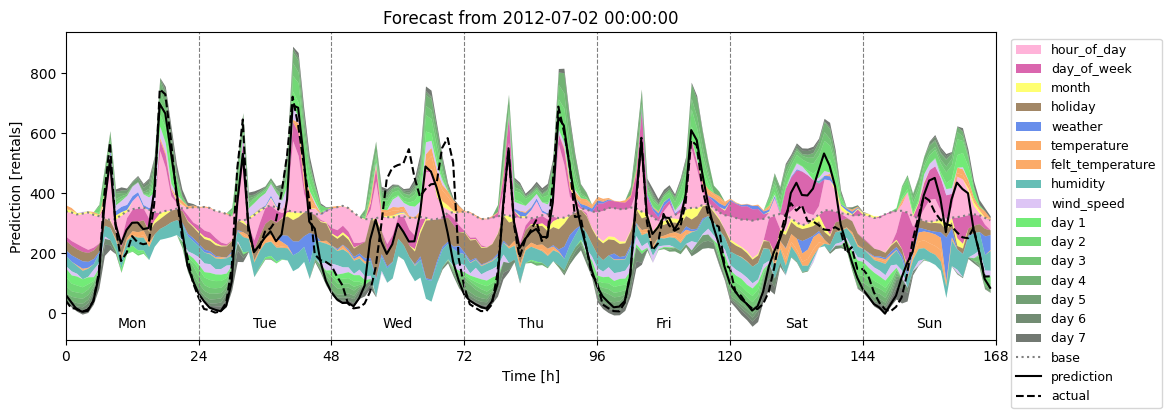

In [9]:
import matplotlib.pyplot as plt
from src.plot import plot_explanation

FORECAST_START = "2012-07-02 00:00:00"
N_PERMUTATIONS_LOCAL = 100
UNIT = "rentals"

start = df.index.get_loc(FORECAST_START)
assert is_complete(start)
past = df.iloc[start - INPUT_LENGTH:start]
future = df.iloc[start:start + HORIZON].drop(columns="rentals")
actual_week = df["rentals"].iloc[start:start + HORIZON]

explanation = model_for(start).explain(past, future, method="permutation", n_permutations=N_PERMUTATIONS_LOCAL,
                                       seed=SEED, progress=False)
plot_explanation(explanation, actual=actual_week, unit=UNIT, title=f"Forecast from {FORECAST_START}")
plt.show()

## Dependence plots of 1000 explanations

We explain 1000 forecasts with random starts (at any hour) in the validation and test period, i.e. in the full year 2012, so that all months are covered. Each forecast is explained with the model of the month in which it starts. Starts whose input or forecast week contains missing values are excluded. We use the fast approximate method `method="permutation"` with `N_PERMUTATIONS` random orders of the feature groups per explanation (each explanation with its own seed for reproducibility). `progress=False` turns off the progress bar of each single explanation; instead, one progress bar shows the progress over all explanations.

A dependence plot shows, for one feature, how its value relates to its contribution: each dot is one explained forecast, with the feature value on the x-axis and its SHAP value at the forecasted hour `DEPENDENCE_HORIZON` (here the 24th hour) on the y-axis. For the rentals, the x-axis is the number of rentals one week before that hour, and the y-axis the sum of the contributions of all seven past days. For categorical features, the red line shows the mean contribution per category. The explanations come from 12 different models, so part of the spread is due to differences between the models.

In [10]:
import math
import random
from tqdm import tqdm
from src.plot import plot_dependence

N_EXPLANATIONS = 1000
N_PERMUTATIONS = 10  # permutations per explanation
DEPENDENCE_HORIZON = 24  # plot the SHAP values of the 24th predicted hour; None plots all 168 hours
N_COLUMNS = 4

# random forecast starts in 2012 without missing values; the past week of the first starts reaches into 2011
first_forecast_start = int((df.index < FIRST_FORECAST_MONTH).sum())
candidates = [s for s in range(first_forecast_start, len(df) - HORIZON + 1) if is_complete(s)]
explanation_starts = random.Random(SEED).sample(candidates, N_EXPLANATIONS)

explanations = [
    model_for(s).explain(df.iloc[s - INPUT_LENGTH:s], df.iloc[s:s + HORIZON].drop(columns="rentals"),
                         method="permutation", n_permutations=N_PERMUTATIONS, seed=SEED + i, progress=False)
    for i, s in enumerate(tqdm(explanation_starts, desc="Explanations"))
]

Explanations:   0%|          | 0/1000 [00:00<?, ?it/s]

Explanations:   0%|          | 1/1000 [00:00<01:49,  9.11it/s]

Explanations:   0%|          | 2/1000 [00:00<01:50,  9.06it/s]

Explanations:   0%|          | 3/1000 [00:00<01:49,  9.07it/s]

Explanations:   0%|          | 4/1000 [00:00<01:55,  8.62it/s]

Explanations:   0%|          | 5/1000 [00:00<01:53,  8.78it/s]

... (992 outputs left out)

Explanations: 100%|█████████▉| 998/1000 [01:54<00:00,  8.54it/s]

Explanations: 100%|█████████▉| 999/1000 [01:54<00:00,  8.70it/s]

Explanations: 100%|██████████| 1000/1000 [01:54<00:00,  8.78it/s]

Explanations: 100%|██████████| 1000/1000 [01:54<00:00,  8.73it/s]

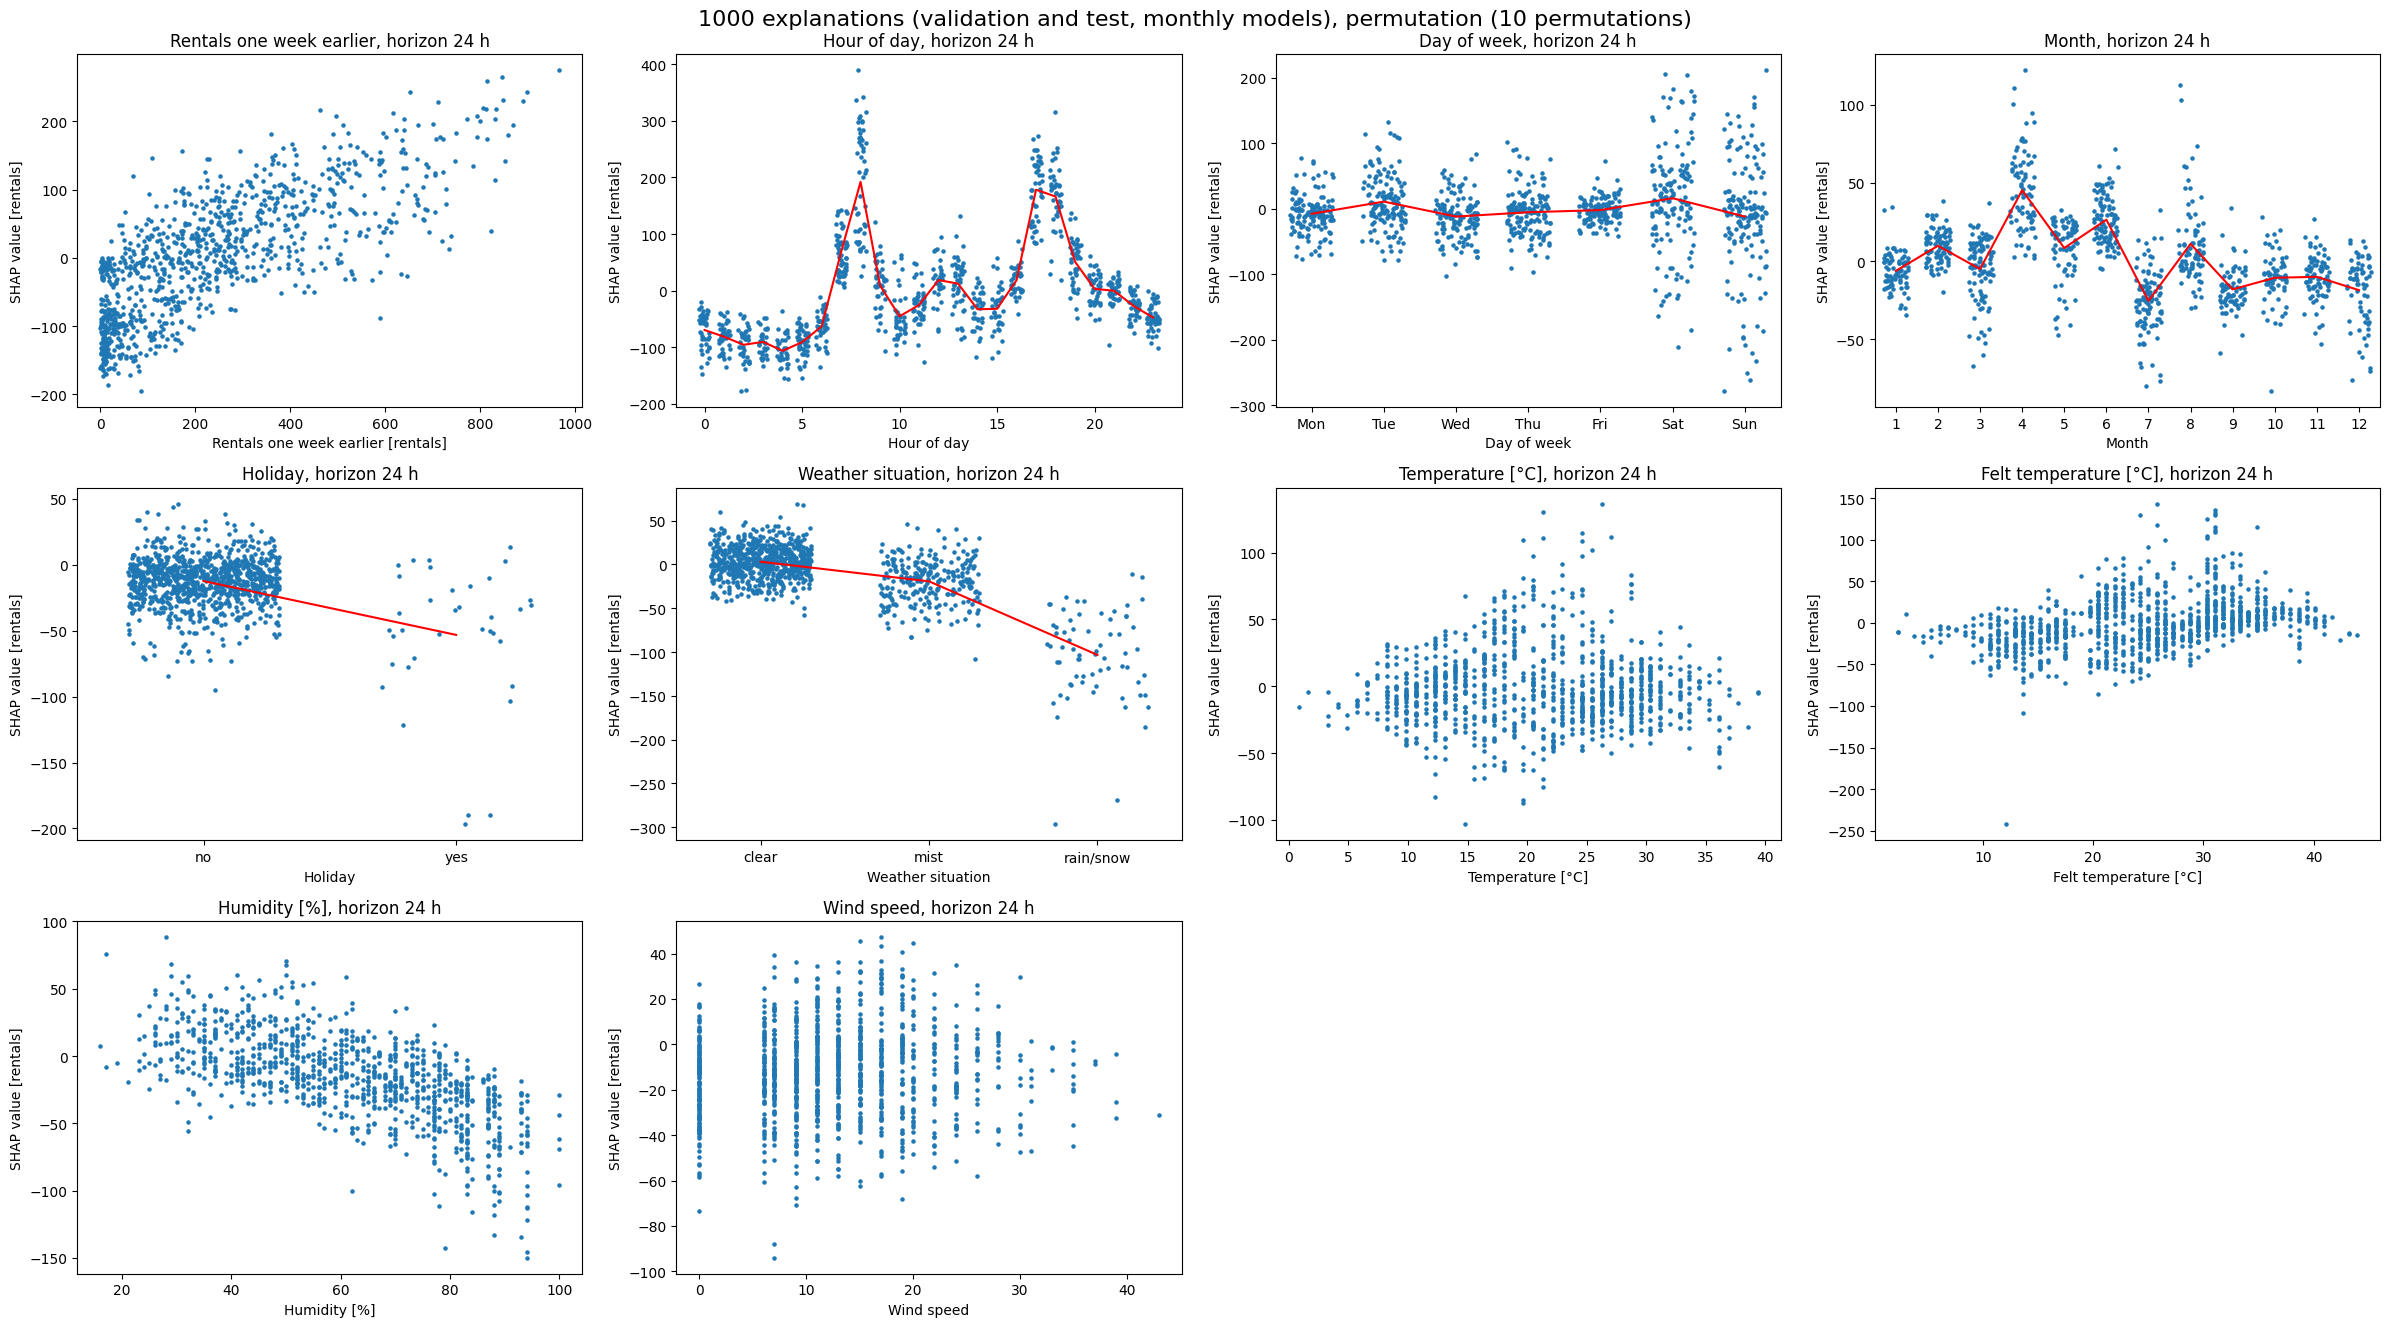

In [11]:
feature_names = next(iter(models.values())).feature_names
n_rows = math.ceil(len(feature_names) / N_COLUMNS)
fig, axs = plt.subplots(n_rows, N_COLUMNS, figsize=(6 * N_COLUMNS, 4.5 * n_rows))
for ax, feature in zip(axs.flat, feature_names):
    plot_dependence(explanations, feature, horizon=DEPENDENCE_HORIZON, unit=UNIT, ax=ax)
for ax in axs.flat[len(feature_names):]:
    ax.set_visible(False)
fig.suptitle(f"{N_EXPLANATIONS} explanations (validation and test, monthly models), "
             f"permutation ({N_PERMUTATIONS} permutations)", fontsize=16)
fig.tight_layout()
plt.show()